In [ ]:
from google.colab import files

uploaded = files.upload()

Saving student_performance_cleaned.xlsx to student_performance_cleaned (1).xlsx
Saving student_performance_uncleaned.xlsx to student_performance_uncleaned.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
raw_file = "/content/student_performance_uncleaned.xlsx"
clean_file = "/content/student_performance_cleaned.xlsx"

# Check whether both files were uploaded
print("Uncleaned file exists:", os.path.exists(raw_file))
print("Cleaned file exists:", os.path.exists(clean_file))

# Display available sheets
print("\nUncleaned workbook sheets:")
print(pd.ExcelFile(raw_file).sheet_names)

print("\nCleaned workbook sheets:")
print(pd.ExcelFile(clean_file).sheet_names)

Uncleaned file exists: True
Cleaned file exists: True

Uncleaned workbook sheets:
['Raw Extracted Lines', 'Source Info']

Cleaned workbook sheets:
['Cleaned Data', 'Cleaning Summary', 'Original Data']


In [ ]:
raw_df = pd.read_excel(
    raw_file,
    sheet_name="Raw Extracted Lines"
)

clean_df = pd.read_excel(
    clean_file,
    sheet_name="Cleaned Data"
)

print("Both datasets loaded successfully!")

print("\nUncleaned data shape:", raw_df.shape)
print("Cleaned data shape:", clean_df.shape)

display(clean_df.head())

Both datasets loaded successfully!

Uncleaned data shape: (2003, 3)
Cleaned data shape: (1002, 8)


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport
0,1.0,John,Male,85.0,15.0,78.0,1.0,High
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium


In [ ]:
print(clean_df.columns.tolist())

['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport']


In [ ]:
clean_df.info()

print("\nMissing values:")
print(clean_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    object 
 2   Gender                     928 non-null    object 
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          949 non-null    float64
 5   PreviousGrade              965 non-null    float64
 6   ExtracurricularActivities  956 non-null    float64
 7   ParentalSupport            936 non-null    object 
dtypes: float64(5), object(3)
memory usage: 62.8+ KB

Missing values:
StudentID                    42
Name                         36
Gender                       74
AttendanceRate               42
StudyHoursPerWeek            53
PreviousGrade                37
ExtracurricularActivities    46
ParentalSupport              66
dtype: i

In [ ]:
print("Duplicate rows:", clean_df.duplicated().sum())

Duplicate rows: 0


In [ ]:
display(clean_df.describe(include="all"))

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport
count,960.000000,966,928,960.000000,949.000000,965.000000,956.000000,936
unique,NaN,949,2,NaN,NaN,NaN,NaN,3
top,NaN,Christopher,Male,NaN,NaN,NaN,NaN,High
freq,NaN,14,490,NaN,NaN,NaN,NaN,334
mean,5416.019792,NaN,NaN,85.510417,17.622761,77.594819,1.521967,NaN
std,2653.748319,NaN,NaN,7.332125,6.270868,10.015992,1.045829,NaN
min,1.000000,NaN,NaN,70.000000,8.000000,60.000000,0.000000,NaN
25%,3113.500000,NaN,NaN,82.000000,12.000000,70.000000,1.000000,NaN
50%,5396.500000,NaN,NaN,88.000000,18.000000,78.000000,1.500000,NaN
75%,7754.750000,NaN,NaN,91.000000,22.000000,86.000000,2.000000,NaN


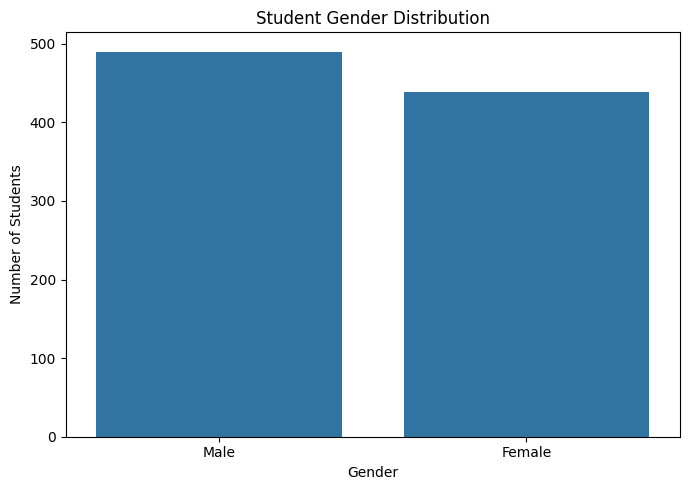

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=clean_df, x="Gender")

plt.title("Student Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

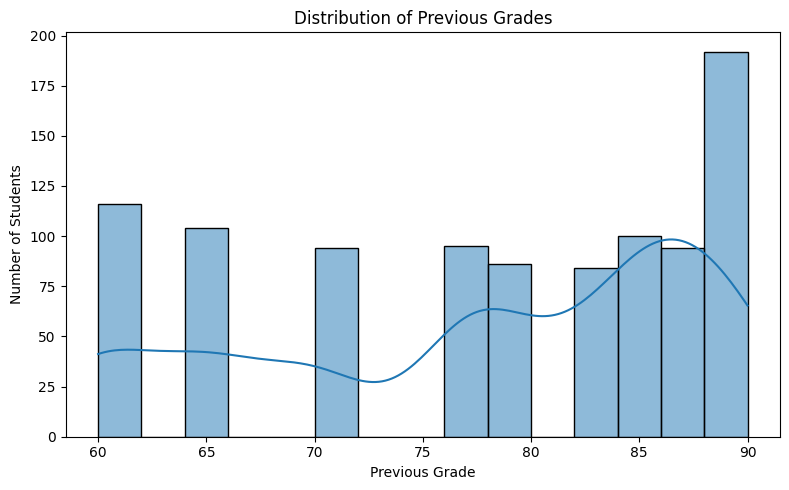

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=clean_df,
    x="PreviousGrade",
    bins=15,
    kde=True
)

plt.title("Distribution of Previous Grades")
plt.xlabel("Previous Grade")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

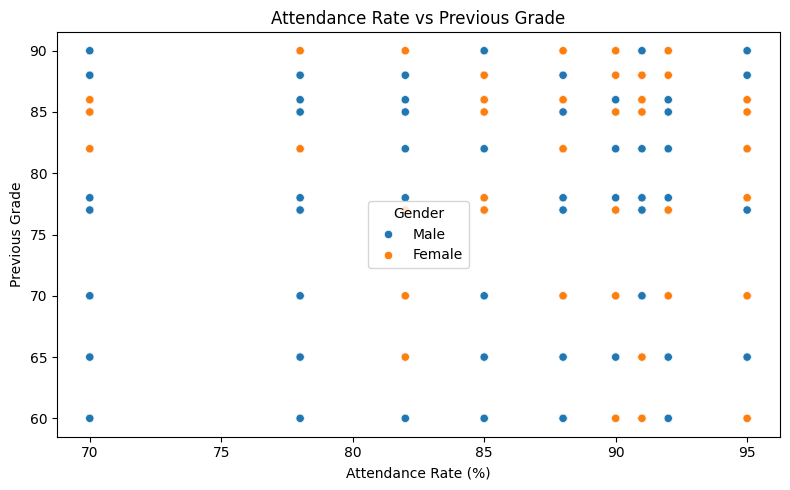

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="AttendanceRate",
    y="PreviousGrade",
    hue="Gender"
)

plt.title("Attendance Rate vs Previous Grade")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Previous Grade")
plt.tight_layout()
plt.show()

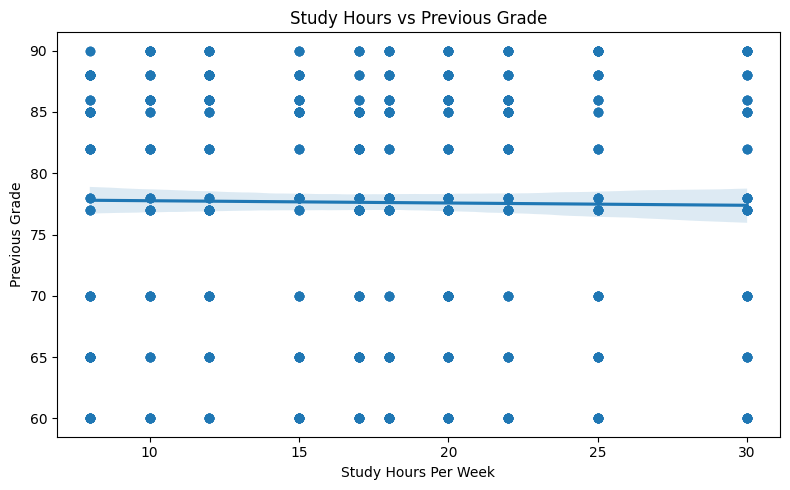

In [ ]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=clean_df,
    x="StudyHoursPerWeek",
    y="PreviousGrade"
)

plt.title("Study Hours vs Previous Grade")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Previous Grade")
plt.tight_layout()
plt.show()

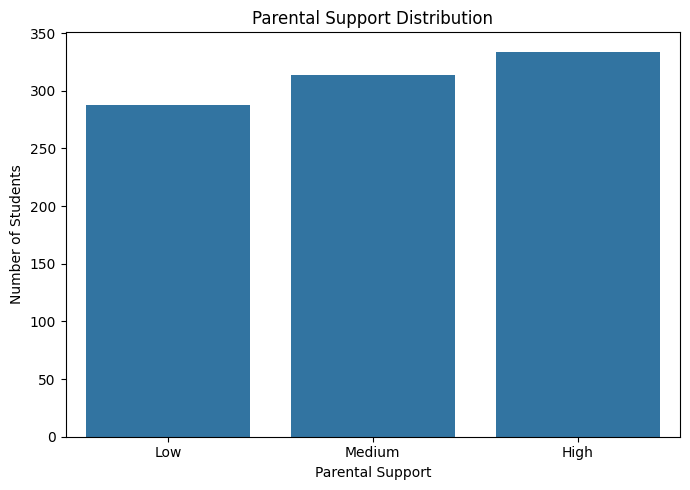

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=clean_df,
    x="ParentalSupport",
    order=["Low", "Medium", "High"]
)

plt.title("Parental Support Distribution")
plt.xlabel("Parental Support")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

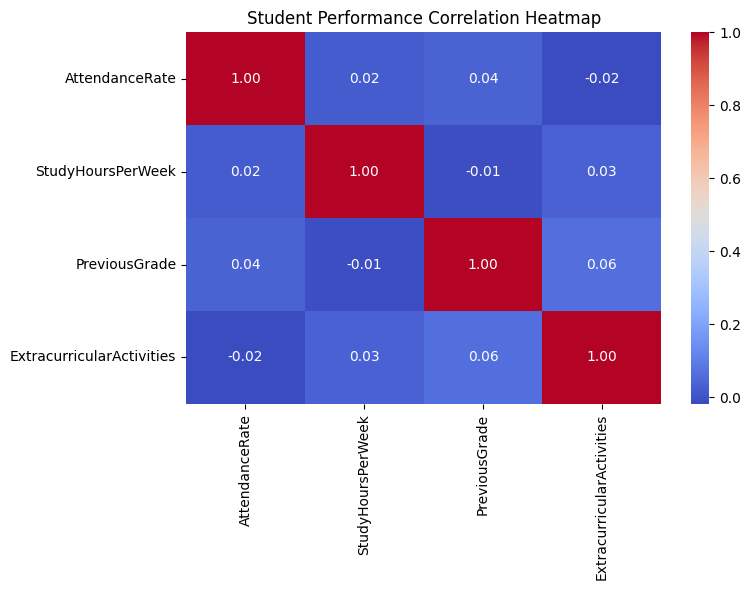

In [ ]:
numeric_columns = [
    "AttendanceRate",
    "StudyHoursPerWeek",
    "PreviousGrade",
    "ExtracurricularActivities"
]

correlation = clean_df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("/content/visualizations", exist_ok=True)

# Gender distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=clean_df, x="Gender")
plt.title("Student Gender Distribution")
plt.tight_layout()
plt.savefig("/content/visualizations/gender_distribution.png", dpi=300)
plt.close()

# Grade distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=clean_df, x="PreviousGrade", bins=15, kde=True)
plt.title("Distribution of Previous Grades")
plt.tight_layout()
plt.savefig("/content/visualizations/grade_distribution.png", dpi=300)
plt.close()

# Attendance vs grades
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clean_df, x="AttendanceRate",
                y="PreviousGrade", hue="Gender")
plt.title("Attendance vs Previous Grade")
plt.tight_layout()
plt.savefig("/content/visualizations/attendance_vs_grade.png", dpi=300)
plt.close()

# Study hours vs grades
plt.figure(figsize=(8, 5))
sns.regplot(data=clean_df, x="StudyHoursPerWeek",
            y="PreviousGrade")
plt.title("Study Hours vs Previous Grade")
plt.tight_layout()
plt.savefig("/content/visualizations/study_hours_vs_grade.png", dpi=300)
plt.close()

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.savefig("/content/visualizations/correlation_heatmap.png", dpi=300)
plt.close()

print("All charts saved successfully!")

All charts saved successfully!


In [ ]:
import shutil

shutil.make_archive(
    "/content/visualizations",
    "zip",
    "/content/visualizations"
)

files.download("/content/visualizations.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>